Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [37]:
# Loading the Amazon UK dataset 
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [38]:
# Retrieving the number of rows and columns in the dataframe
df.shape

(2443651, 9)

In [39]:
# Displaying the data types of each column in the dataframe
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [40]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

## Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1.Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

In [41]:
# Frequency table for 'category'
frequency_table = df['category'].value_counts().head()

# Calculating the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True).head()

frequency_table, proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
 Name: count, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
 Name: proportion, dtype: float64)

## 2. Visualizations: 

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [42]:
# Creating a crosstab table for the 'category' column, counting occurrences for each unique value
my_table = pd.crosstab(index = df["category"],  # Make a crosstab
                              columns="count").head(5)    # Name the count column
my_table

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254


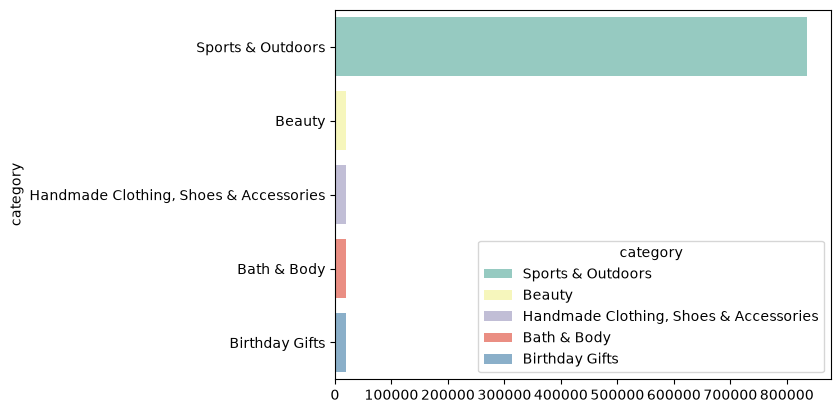

In [43]:
# Plotting a bar chart using the values from the frequency table, with colors sourced from the "Set3" palette
ax=sns.barplot(y=frequency_table.index, x=frequency_table.values, palette="Set3", hue=frequency_table.index, legend=True )
sns.move_legend(ax, "lower right")

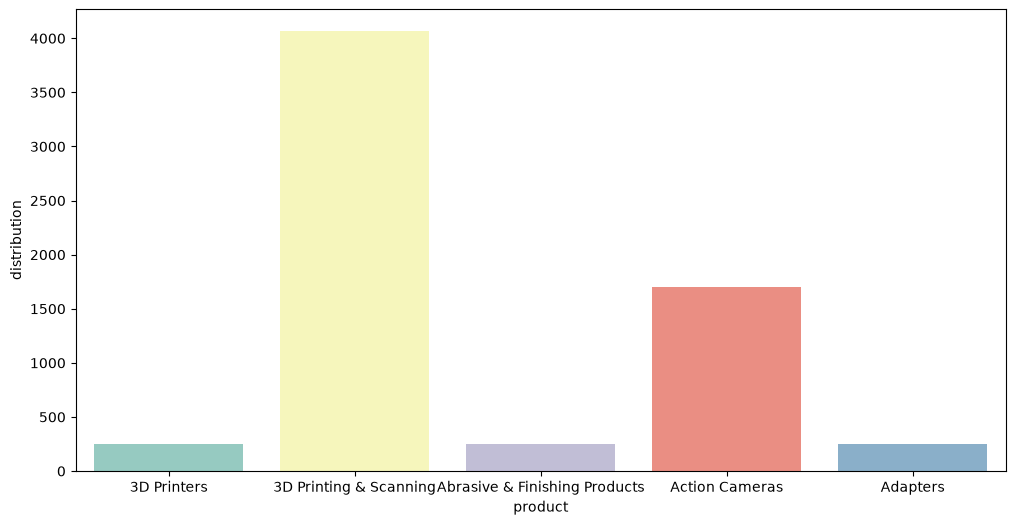

In [44]:
# Plotting a bar chart using the 'count' values from 'my_table', with colors sourced from the "Set3" palette
fig, axes = plt.subplots(figsize=(12,6))
sns.barplot(x=my_table.index, y=my_table["count"], palette="Set3",hue=my_table.index, legend=False, ax=axes)
axes.set_ylabel("distribution")
axes.set_xlabel("product")
plt.show()

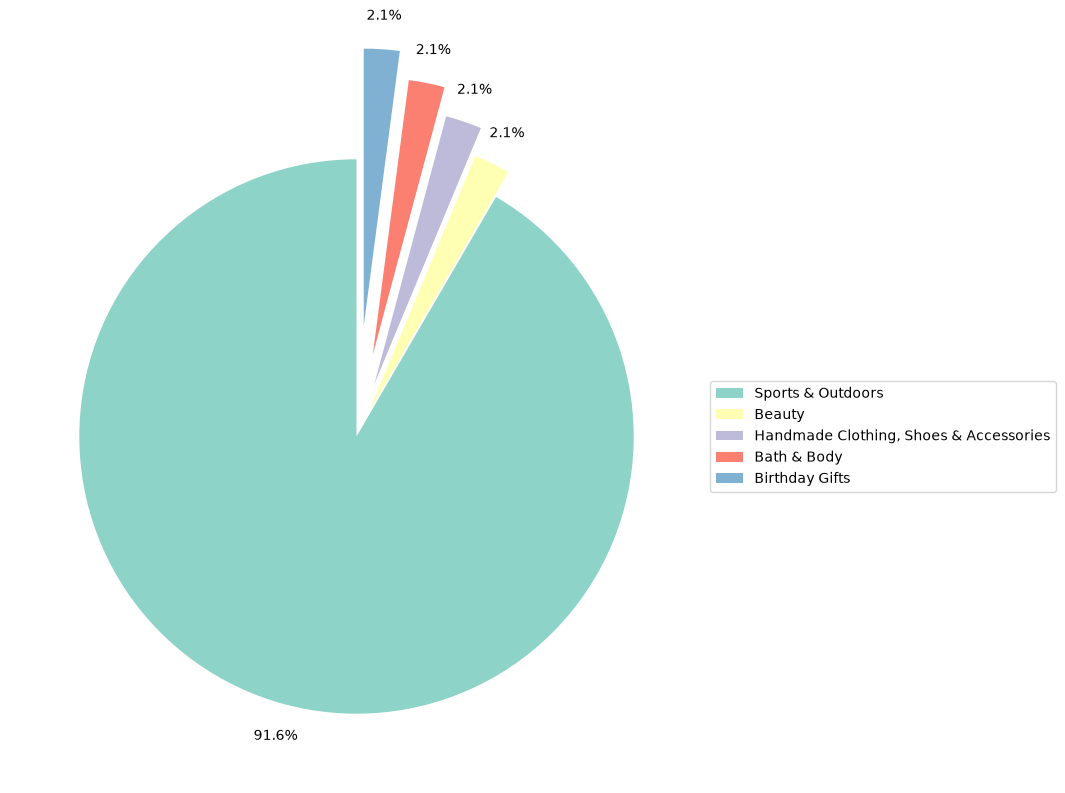

In [45]:
# Plotting a pie chart of the 'category' column value counts, with percentage labels,
# starting at angle 90, and using colors from the "Set3" Seaborn palette
counts = df['category'].value_counts().head()

fig, ax = plt.subplots(figsize=(9, 9))
counts.plot.pie(
    autopct='%.1f%%',
    startangle=90,
    explode=[0, 0.1, 0.2, 0.3, 0.4],   # pops each slice out more than the last
    pctdistance=1.12,                  # percentages sit outside the pie
    labels=None,                       # remove names from the slices
    ax=ax,
    colors=sns.color_palette("Set3")
)
ax.legend(counts.index, loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_ylabel('')
plt.show() # Sports & Outdoors dominates the listings

## Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 1. Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [46]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price
# $89.24 is the average price of products.
# The most common price of products is around $10.
# Mean is higher than mode, most products are clustered around 10. A small number of expensive products pull the average up. Distribution is rightly skewed.
# Most products are cheap around $ 20, but a few extreme prices, upto $ 100000.

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

### 2. Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [47]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price
# std dev = $345 and variance = $119445 are huge compared to mean = $ 89. The price range is very varied.
# range price = $100000, so the prices are spread over a wide range
# IQR = 45.99 - 9.99. The middle 50% of products cost only between $10 and $46.


(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(0.0),
 np.float64(100000.0),
 np.float64(100000.0),
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

### 3.Visualizations:
Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

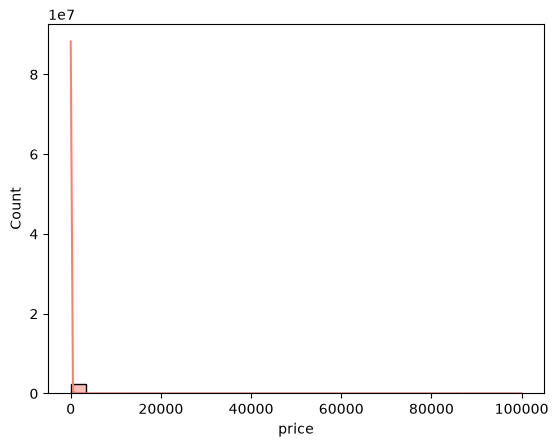

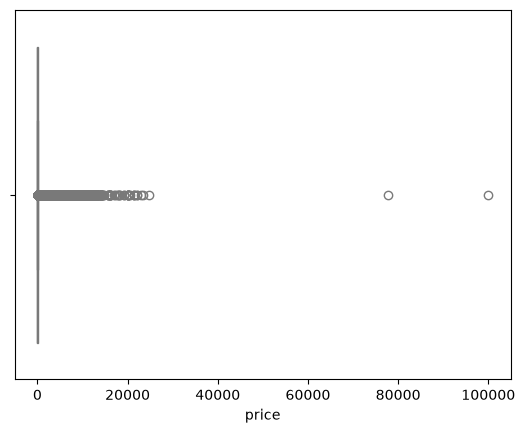

In [54]:
# Plotting a histogram for the 'price' column of the 'data' dataframe
# 'kde=True' adds a Kernel Density Estimate plot to give an approximation of the data's distribution
# 'bins=30' divides the data into 30 bins for more detailed granularity
# 'color="salmon"' sets the color of the bars to salmon
fig, axes = plt.subplots()
sns.histplot(df['price'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()
# Its hard to read histogram because of very high right-skewed price values. Most of the products cost around $50, but some outliers cost around $1,00,000 and around $78,000.

### Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

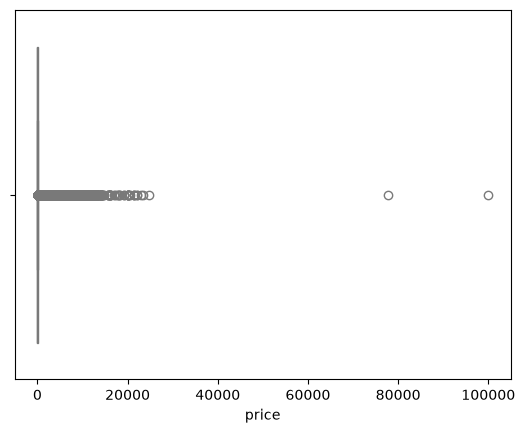

In [55]:
# Plotting a boxplot for the 'price' column with a light blue color
sns.boxplot(x = df['price'], color="lightblue");
# yes.there are products that are priced significantly higher than the res. Can spot the outliers clearly by this box plot.

# Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?
1. Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.


In [57]:
#df['stars'].value_counts()
# A lot of products do not have ratings given.
mean_ratings = df['stars'].mean()
median_ratings = df['stars'].median()
mode_ratings = df['stars'].mode()[0]
mean_ratings, median_ratings, mode_ratings

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

How do customers generally rate products? Is there a common trend?
Insights:  
Most products have no rating .That's why the mean and median values are zero.
Mean is pulled down to 2.15 because Most products have no rating even though some products have given high (4 to 5) ratings.


Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [76]:
variance_ratings = df['stars'].var()
std_ratings = df['stars'].std()
quantiles_ratings = df['stars'].quantile([0.25, 0.5, 0.75])
IQR = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)
variance_ratings,std_ratings,quantiles_ratings,IQR

(np.float64(4.817434029796864),
 np.float64(2.194865378513421),
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64,
 np.float64(4.4))

Insights: There a wide variation in customer feedback.The spread is large, but this is caused by no ratings mixed with high ratings. The variation comes from rated products to non rated products so the
ratings are not inconsistent in the sense of customer disagreeing

### Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [78]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

Insights:

Skewness: The skewness is near to 0, that is 0.08 for the 'stars' means no real lean toward higher or lower ratings and indicates that the distribution is symmetric as the zeros and 4-5 ratings balance each other out.

Kurtosis: The kurtosis value of -1.92 is lesser than 0, which indicates that the 'stars' distribution has light tails and a flat distrobution compared to a normal rating. This means that there are more no ratings in the 'stars' than expected .



4.Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


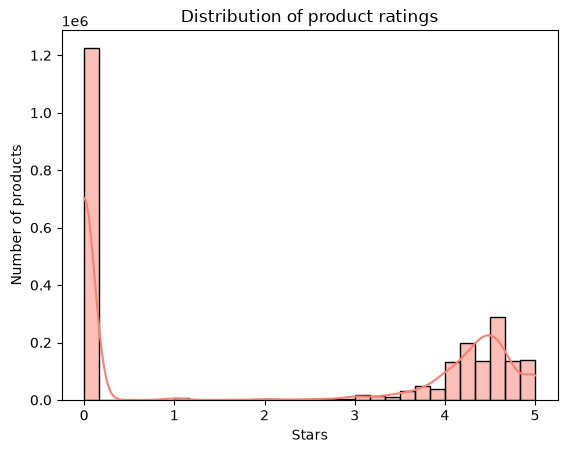

In [81]:
fig, axes = plt.subplots()
sns.histplot(df['stars'], kde=True, bins=30, color="salmon", ax=axes);
axes.set_title("Distribution of product ratings")
axes.set_xlabel("Stars")
axes.set_ylabel("Number of products(millions)")
plt.show()


Insights: 
The most common rating is zero rating that is no rating is given. In the between ratings like 1 to 3 there are no significant rating counts. Most of the give ratings are from 4 to 5.

In [ ]:
## Discretizing 'stars' into 5 categories
#bins = [0, 1, 2, 3,4,df['stars'].max()]
#labels = ['Null','Low', 'Medium', 'High', 'Very High']
#df['rating_category'] = pd.cut(df['stars'], bins=bins, labels=labels, include_lowest=True)

In [ ]:
#df.rating_category.value_counts()